# Oxford-IIIT Pet — 37-breed classifier (PyTorch transfer learning)

**Goal:** classify images of 37 cat and dog breeds (12 cat, 25 dog) from the [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/) dataset.

**Strategy**
1. Stratified 80/20 split of the official `trainval` set (3,680 images) into train / validation. The official `test` split (3,669 images) is used **only once**, at the very end.
2. ImageNet-pretrained backbone: ResNet-50 on a CUDA GPU, EfficientNet-B0 otherwise.
3. **Stage 1:** freeze the backbone and train only the new classification head.
4. **Stage 2:** unfreeze everything and fine-tune with discriminative learning rates, a OneCycle schedule, label smoothing and early stopping.
5. Evaluate on the test split: accuracy, top-5, macro-F1, per-class report, confusion matrix and error analysis.

**Final result:** 93.1 % top-1, 99.4 % top-5 test accuracy (ResNet-50).

### Imports

In [ ]:
import random, time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt
from PIL import Image

## Setup: reproducibility, device and configuration

- `seed_everything` fixes the Python, NumPy and PyTorch random seeds so that the data split and weight initialisation are repeatable.
- The device is picked automatically: CUDA GPU → Apple MPS → CPU.
- All hyperparameters live in the `CFG` dictionary so they can be changed in one place. Off-GPU the notebook switches to the lighter EfficientNet-B0.

In [ ]:
SEED = 42
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("Device:", DEVICE, "| torch", torch.__version__)

CFG = dict(
    arch="resnet50" if DEVICE.type == "cuda" else "efficientnet_b0",  # lighter model off-GPU
    data_root="data",
    img_size=224,
    batch_size=32,
    num_workers=2,
    val_frac=0.2,
    head_epochs=3,        # stage 1: head only
    ft_epochs=12,         # stage 2: full fine-tune (max; early stopping may end sooner)
    head_lr=1e-3,
    backbone_lr=1e-4,
    weight_decay=1e-4,
    label_smoothing=0.1,
    patience=4,
    ckpt="best_pet_model.pt",
)
CFG

Device: cuda | torch 2.11.0+cu130


{'arch': 'resnet50',
 'data_root': 'data',
 'img_size': 224,
 'batch_size': 32,
 'num_workers': 2,
 'val_frac': 0.2,
 'head_epochs': 3,
 'ft_epochs': 12,
 'head_lr': 0.001,
 'backbone_lr': 0.0001,
 'weight_decay': 0.0001,
 'label_smoothing': 0.1,
 'patience': 4,
 'ckpt': 'best_pet_model.pt'}

## 1. Data

### 1.1 Image transforms

Both pipelines normalise with the **ImageNet mean and standard deviation**, because the pretrained backbone expects inputs on that scale.

- **Training** uses data augmentation to reduce overfitting: a random crop that keeps 60–100 % of the image, a random horizontal flip, and `TrivialAugmentWide`, which applies one randomly chosen photometric or geometric operation per image.
- **Evaluation** (validation and test) is deterministic: resize to 256 px, then take a 224 px centre crop.

In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(CFG["img_size"], scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(CFG["img_size"]),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

### 1.2 Load the dataset

The dataset (~800 MB) downloads on the first run. `trainval` is loaded **twice** on the same files: once with the augmented transform (for training) and once with the clean transform (for validation). This way validation images are never augmented.

In [ ]:
trainval_aug = datasets.OxfordIIITPet(root=CFG["data_root"], split="trainval", transform=train_tf, target_types="category",download=True)
trainval_eval = datasets.OxfordIIITPet(root=CFG["data_root"], split="trainval", transform=eval_tf, target_types='category',download=False)
test_ds = datasets.OxfordIIITPet(root=CFG["data_root"], split="test", target_types='category',transform=eval_tf, download=True)

100%|██████████| 792M/792M [00:25<00:00, 31.1MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 18.8MB/s]


### 1.3 Stratified train / validation split

`train_test_split(..., stratify=labels)` holds out 20 % of `trainval` for validation while keeping the same proportion of every breed in both parts. The labels are read from the dataset's internal `_labels` list, so no images need to be decoded to make the split.

Training indices point into the augmented copy and validation indices into the clean copy.

In [ ]:
CLASSES = trainval_aug.classes
NUM_CLASSES = len(CLASSES)

labels = np.array(trainval_aug._labels)
train_idx, val_idx = train_test_split(np.arange(len(labels)), test_size=CFG["val_frac"], stratify=labels, random_state=SEED)

train_ds = Subset(trainval_aug, train_idx)
val_ds = Subset(trainval_eval, val_idx)


### 1.4 Data loaders

Shared loader settings. `pin_memory` speeds up host-to-GPU transfers and is only enabled on CUDA.

In [ ]:
loader_kw = dict(batch_size=CFG["batch_size"], num_workers=CFG["num_workers"],
                 pin_memory=DEVICE.type == "cuda")

Only the training loader shuffles. `drop_last=True` discards the final incomplete batch, so every training step uses a full batch.

In [ ]:
train_loader = DataLoader(train_ds, shuffle=True, drop_last=True, **loader_kw)
val_loader = DataLoader(val_ds, shuffle=False, **loader_kw)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kw)


Sanity check of split sizes and class balance. Each breed has 93–100 `trainval` images, so the classes are nearly balanced and plain accuracy is a fair headline metric.

In [ ]:
print(f"{NUM_CLASSES} classes | train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}")
print("Images per class (trainval):", np.bincount(labels).min(), "-", np.bincount(labels).max())

37 classes | train 2944 | val 736 | test 3669
Images per class (trainval): 93 - 100


### 1.5 Visual check of the augmented training batch

`denorm` reverses the ImageNet normalisation so the images can be displayed. This confirms that the augmentations look reasonable and that the labels match the pictures.

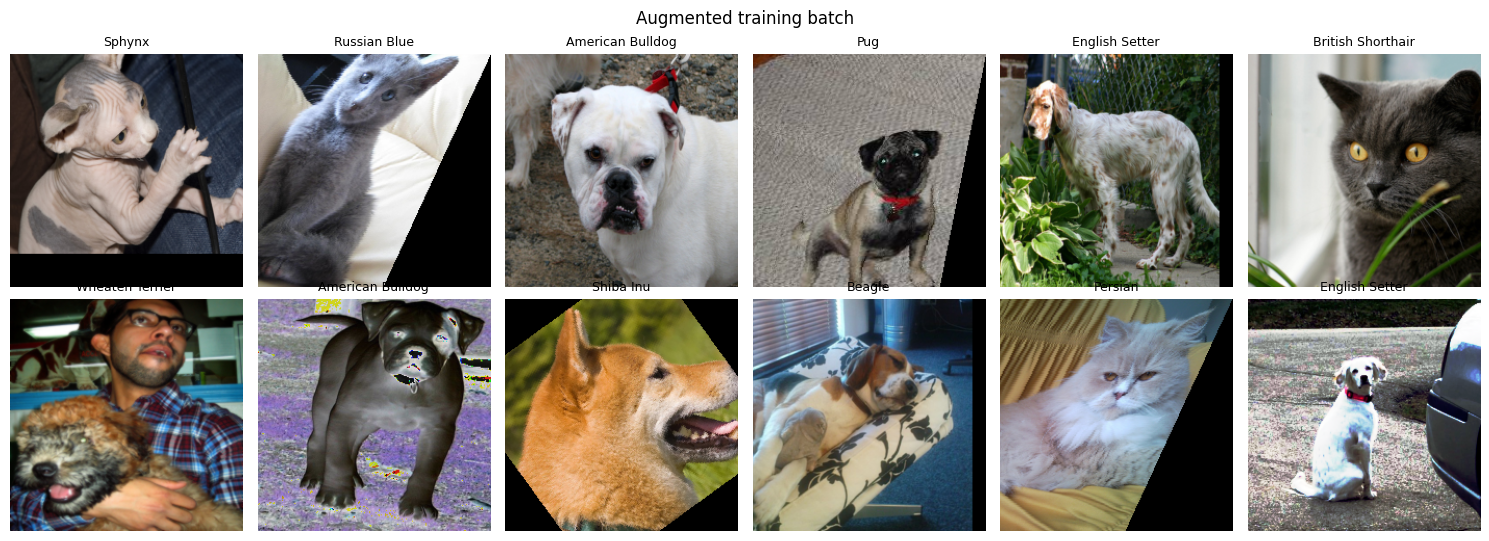

In [ ]:
def denorm(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

xb, yb = next(iter(train_loader))
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, img, y in zip(axes.flat, xb, yb):
    ax.imshow(denorm(img)); ax.set_title(CLASSES[y], fontsize=9); ax.axis("off")
plt.suptitle("Augmented training batch"); plt.tight_layout(); plt.show()

## 2. Model

The original 1000-class ImageNet classifier is replaced with a new 37-class head:
- **ResNet-50** (`IMAGENET1K_V2` weights): `Dropout(0.3) → Linear(2048, 37)`
- **EfficientNet-B0**: the last linear layer is swapped for a 37-way one

The helper functions split the parameters into **head** and **backbone** groups. This lets us freeze the backbone in stage 1 and give the two groups different learning rates in stage 2.

In [ ]:
def build_model(arch, num_classes):
    if arch == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, num_classes))
        head = "fc"
    elif arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
        head = "classifier"
    else:
        raise ValueError(arch)
    return m, head

model, HEAD = build_model(CFG["arch"], NUM_CLASSES)
model = model.to(DEVICE)

def head_params(m):     return [p for n, p in m.named_parameters() if n.startswith(HEAD + ".")]
def backbone_params(m): return [p for n, p in m.named_parameters() if not n.startswith(HEAD + ".")]
def set_backbone_trainable(m, trainable):
    for p in backbone_params(m): p.requires_grad = trainable

n_params = sum(p.numel() for p in model.parameters())
print(f"{CFG['arch']}: {n_params/1e6:.1f}M parameters, head = '{HEAD}'")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 239MB/s]

resnet50: 23.6M parameters, head = 'fc'


## 3. Training utilities

- **Loss:** cross-entropy with **label smoothing (0.1)**. This discourages over-confident predictions, which helps with near-identical breeds.
- **Mixed precision (AMP):** on CUDA, forward passes run in float16 with a gradient scaler, for faster training and lower memory use.
- `run_epoch` performs one pass over a loader. It trains when an optimiser is given and evaluates otherwise, and returns the mean loss and accuracy.
- `fit` runs several epochs, records the history, **saves a checkpoint whenever validation accuracy improves**, and stops early after `patience` epochs without improvement.

In [ ]:
USE_AMP = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
criterion = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])

def run_epoch(model, loader, optimizer=None, scheduler=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
                loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                if scheduler is not None:
                    scheduler.step()
            total_loss += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history = {"stage": [], "train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best = {"val_acc": 0.0, "epoch": -1}

def fit(model, epochs, optimizer, scheduler, stage):
    bad_epochs = 0
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer, scheduler)
        va_loss, va_acc = run_epoch(model, val_loader)
        for k, v in zip(history, [stage, tr_loss, tr_acc, va_loss, va_acc]):
            history[k].append(v)
        flag = ""
        if va_acc > best["val_acc"]:
            best.update(val_acc=va_acc, epoch=len(history["val_acc"]))
            torch.save(model.state_dict(), CFG["ckpt"])
            bad_epochs, flag = 0, "  ✓ saved"
        else:
            bad_epochs += 1
        print(f"[{stage}] ep {ep+1:02d}/{epochs} | train {tr_loss:.3f} / {tr_acc:.3f} | "
              f"val {va_loss:.3f} / {va_acc:.3f} | {time.time()-t0:.0f}s{flag}")
        if bad_epochs >= CFG["patience"]:
            print(f"Early stopping: no val improvement for {CFG['patience']} epochs")
            break

## 4. Stage 1 — train the head only (frozen backbone)

The new head starts from random weights. Training it alone first means its large early gradients cannot damage the pretrained backbone features. This is effectively a *linear probe* of the ImageNet features, and it already reaches ~92 % validation accuracy.

> Training accuracy is measured on augmented images, so early on it is often *below* validation accuracy. This is expected.

In [ ]:
set_backbone_trainable(model, False)
opt = torch.optim.AdamW(head_params(model), lr=CFG["head_lr"], weight_decay=CFG["weight_decay"])
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["head_lr"],
                                            total_steps=CFG["head_epochs"] * len(train_loader))
fit(model, CFG["head_epochs"], opt, sched, stage="head")

[head] ep 01/3 | train 3.130 / 0.342 | val 2.153 / 0.864 | 8s  ✓ saved
[head] ep 02/3 | train 1.726 / 0.847 | val 1.382 / 0.917 | 5s  ✓ saved
[head] ep 03/3 | train 1.397 / 0.878 | val 1.307 / 0.918 | 5s  ✓ saved


## 5. Stage 2 — fine-tune the whole network (discriminative learning rates)

All layers are unfrozen and trained with two parameter groups:
- **backbone:** lr = 1e-4 (small, to adapt the pretrained features gently)
- **head:** lr = 5e-4

`OneCycleLR` warms the learning rate up over the first 20 % of steps and then anneals it. Note that the printed *best epoch* counts both stages (3 head epochs + fine-tuning epochs).

In [ ]:
set_backbone_trainable(model, True)
opt = torch.optim.AdamW([
    {"params": backbone_params(model), "lr": CFG["backbone_lr"]},
    {"params": head_params(model),     "lr": CFG["head_lr"] / 2},
], weight_decay=CFG["weight_decay"])
sched = torch.optim.lr_scheduler.OneCycleLR(
    opt, max_lr=[CFG["backbone_lr"], CFG["head_lr"] / 2],
    total_steps=CFG["ft_epochs"] * len(train_loader), pct_start=0.2)
fit(model, CFG["ft_epochs"], opt, sched, stage="finetune")
print(f"Best val acc {best['val_acc']:.4f} at epoch {best['epoch']}")

[finetune] ep 01/12 | train 1.224 / 0.894 | val 0.992 / 0.933 | 5s  ✓ saved
[finetune] ep 02/12 | train 1.012 / 0.920 | val 0.918 / 0.939 | 5s  ✓ saved
[finetune] ep 03/12 | train 0.906 / 0.950 | val 0.878 / 0.942 | 5s  ✓ saved
[finetune] ep 04/12 | train 0.850 / 0.963 | val 0.864 / 0.947 | 5s  ✓ saved
[finetune] ep 05/12 | train 0.823 / 0.970 | val 0.862 / 0.942 | 4s
[finetune] ep 06/12 | train 0.802 / 0.974 | val 0.847 / 0.951 | 5s  ✓ saved
[finetune] ep 07/12 | train 0.788 / 0.974 | val 0.847 / 0.950 | 5s
[finetune] ep 08/12 | train 0.761 / 0.986 | val 0.839 / 0.952 | 4s  ✓ saved
[finetune] ep 09/12 | train 0.748 / 0.990 | val 0.843 / 0.950 | 5s
[finetune] ep 10/12 | train 0.749 / 0.987 | val 0.840 / 0.951 | 4s
[finetune] ep 11/12 | train 0.741 / 0.990 | val 0.839 / 0.954 | 5s  ✓ saved
[finetune] ep 12/12 | train 0.739 / 0.990 | val 0.837 / 0.952 | 5s
Best val acc 0.9538 at epoch 14


### Training curves

Loss and accuracy per epoch. The dashed line marks the switch from stage 1 (head only) to stage 2 (full fine-tuning).

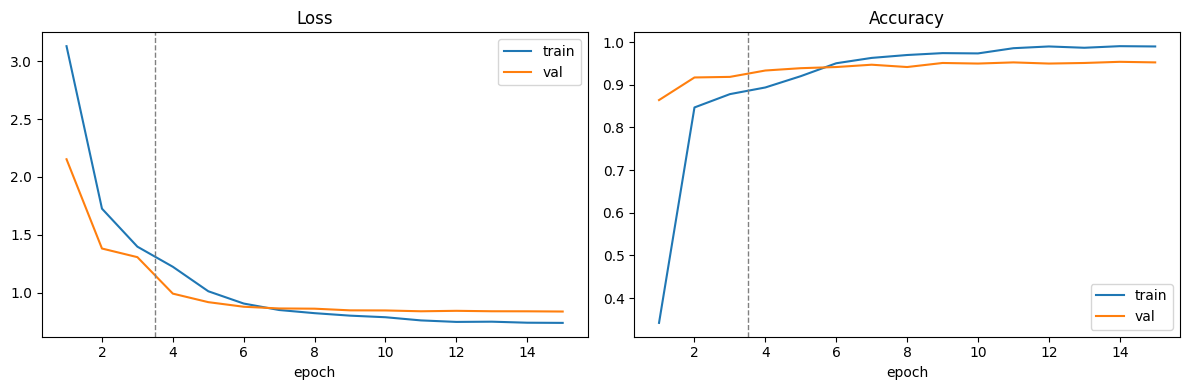

In [ ]:
ep = np.arange(1, len(history["val_acc"]) + 1)
n_head = history["stage"].count("head")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(ep, history["train_loss"], label="train"); a1.plot(ep, history["val_loss"], label="val")
a2.plot(ep, history["train_acc"], label="train"); a2.plot(ep, history["val_acc"], label="val")
for a, t in [(a1, "Loss"), (a2, "Accuracy")]:
    a.axvline(n_head + 0.5, ls="--", c="grey", lw=1); a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## 6. Final evaluation on the held-out test split (run once)

The **best checkpoint** (by validation accuracy) is reloaded and evaluated on the official test split, which has not been used until now. Reported metrics:
- **Top-1 accuracy** and **top-5 accuracy** (the true breed is among the 5 most probable)
- **Macro F1**: the unweighted mean of per-class F1
- A per-class precision / recall / F1 report

In [ ]:
model.load_state_dict(torch.load(CFG["ckpt"], map_location=DEVICE))
model.eval()

all_logits, all_y = [], []
with torch.no_grad():
    for x, y in test_loader:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            all_logits.append(model(x.to(DEVICE)).float().cpu())
        all_y.append(y)
logits = torch.cat(all_logits); y_true = torch.cat(all_y).numpy()
probs = logits.softmax(1).numpy(); y_pred = probs.argmax(1)

top5 = (np.argsort(-probs, 1)[:, :5] == y_true[:, None]).any(1).mean()
print(f"Test accuracy : {(y_pred == y_true).mean():.4f}")
print(f"Top-5 accuracy: {top5:.4f}")
print(f"Macro F1      : {f1_score(y_true, y_pred, average='macro'):.4f}\n")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

Test accuracy : 0.9313
Top-5 accuracy: 0.9940
Macro F1      : 0.9302

                            precision    recall  f1-score   support

                Abyssinian      0.935     0.888     0.911        98
          American Bulldog      0.722     0.960     0.824       100
 American Pit Bull Terrier      0.851     0.570     0.683       100
              Basset Hound      0.960     0.960     0.960       100
                    Beagle      0.949     0.940     0.945       100
                    Bengal      0.754     0.920     0.829       100
                    Birman      0.824     0.890     0.856       100
                    Bombay      0.898     1.000     0.946        88
                     Boxer      0.959     0.939     0.949        99
         British Shorthair      0.956     0.860     0.905       100
                 Chihuahua      0.939     0.930     0.935       100
              Egyptian Mau      0.922     0.856     0.888        97
    English Cocker Spaniel      0.990     0.9

### Confusion matrix and most-confused breed pairs

The matrix is **row-normalised**: each row shows how the images of one true breed were distributed across the predictions, with the diagonal giving per-class recall. Below it we list the 10 largest off-diagonal counts.

Most errors fall in two groups of visually similar breeds: the *bully breeds* (American Pit Bull Terrier, Staffordshire Bull Terrier, American Bulldog) and *long-haired or spotted cats* (Ragdoll, Birman, Maine Coon, Bengal, Egyptian Mau).

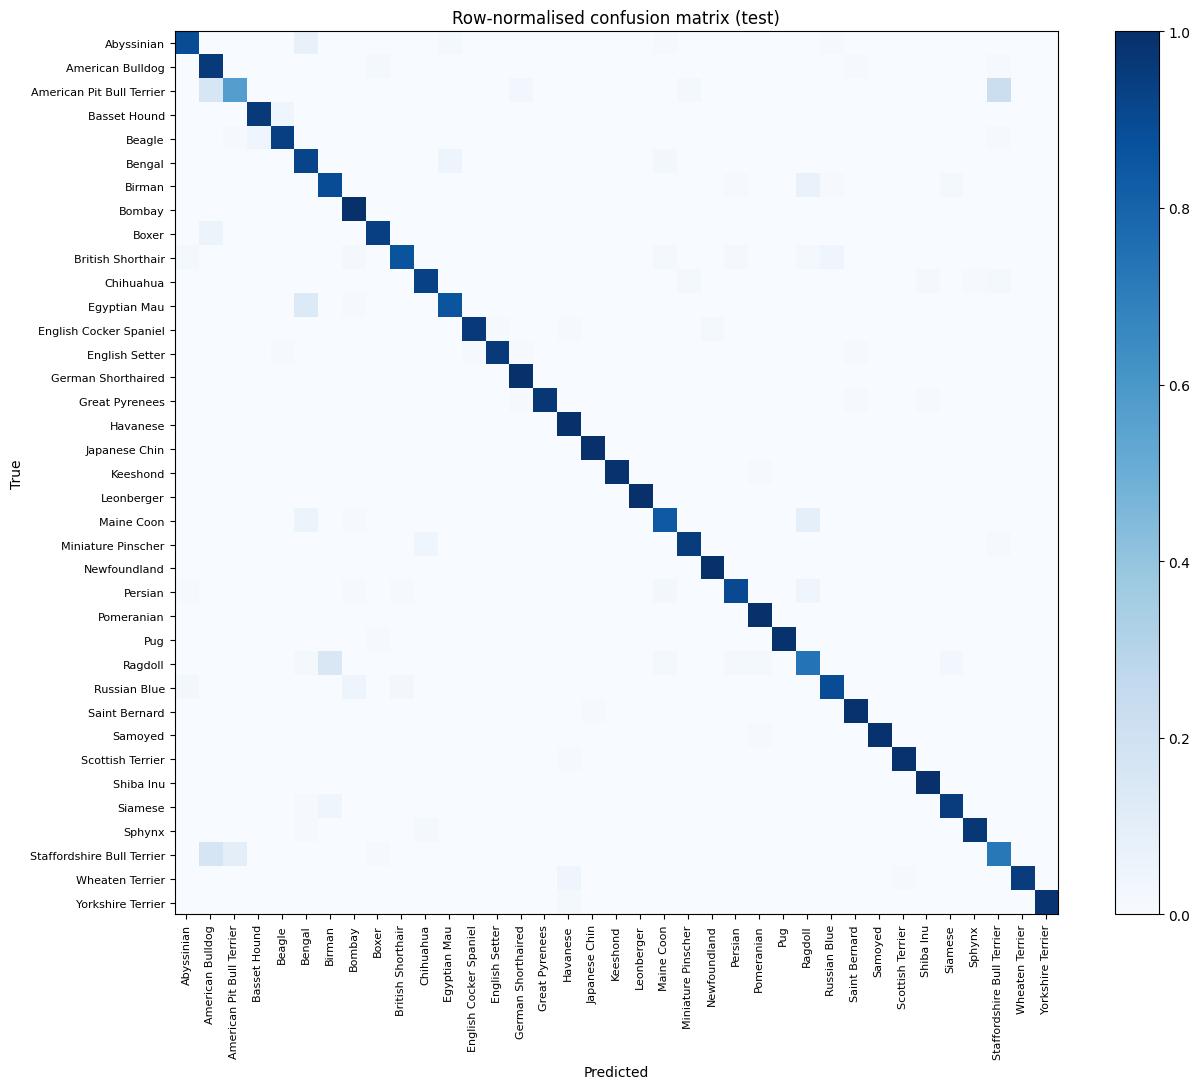

Most confused (true → predicted):
   22  American Pit Bull Terrier → Staffordshire Bull Terrier
   16  American Pit Bull Terrier → American Bulldog
   15  Staffordshire Bull Terrier → American Bulldog
   15  Ragdoll → Birman
   13  Egyptian Mau → Bengal
    9  Staffordshire Bull Terrier → American Pit Bull Terrier
    9  Maine Coon → Ragdoll
    7  Birman → Ragdoll
    7  Abyssinian → Bengal
    6  Maine Coon → Bengal


In [ ]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=90, fontsize=8)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES, fontsize=8)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Row-normalised confusion matrix (test)")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], CLASSES[i], CLASSES[j]) for i in range(NUM_CLASSES)
                for j in range(NUM_CLASSES) if off[i, j] > 0), reverse=True)[:10]
print("Most confused (true → predicted):")
for n, t, p in pairs:
    print(f"  {n:3d}  {t} → {p}")

### Most confident mistakes

The 12 test images the model got wrong with the **highest confidence**. Inspecting them shows whether the errors are genuinely ambiguous images, label noise, or failures driven by background or pose. (T = true breed, P = predicted breed with its probability.)

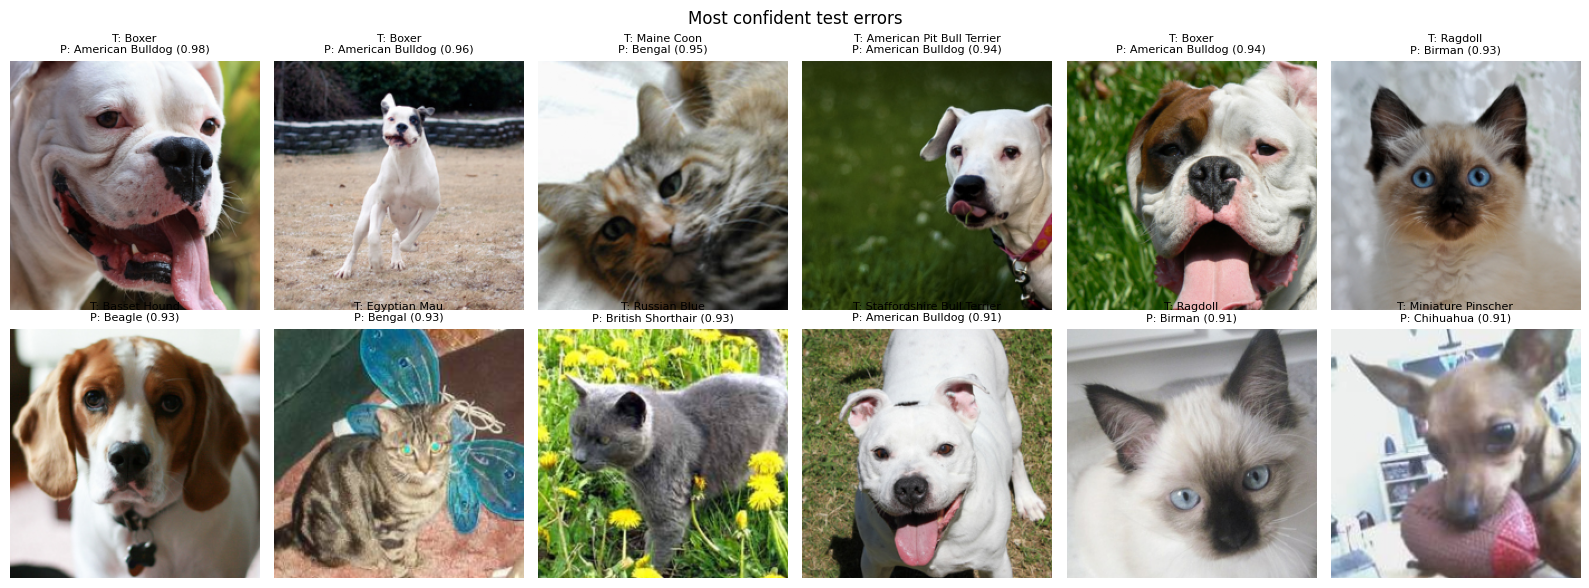

In [ ]:
# Most confident mistakes
wrong = np.where(y_pred != y_true)[0]
wrong = wrong[np.argsort(-probs[wrong, y_pred[wrong]])][:12]
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, i in zip(axes.flat, wrong):
    img, _ = test_ds[i]
    ax.imshow(denorm(img)); ax.axis("off")
    ax.set_title(f"T: {CLASSES[y_true[i]]}\nP: {CLASSES[y_pred[i]]} ({probs[i, y_pred[i]]:.2f})", fontsize=8)
plt.suptitle("Most confident test errors"); plt.tight_layout(); plt.show()

## 7. Predict on your own photo

`predict_image` applies the evaluation transform to any image file and prints the top-5 breeds with their probabilities. Replace the path with your own image; the example below is a pug photo uploaded to the Colab session.

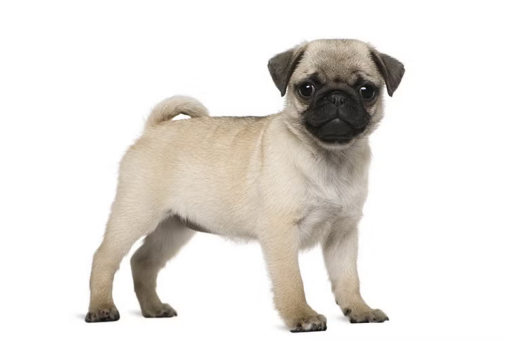

Pug                          0.946
Siamese                      0.003
Shiba Inu                    0.003
Chihuahua                    0.003
Persian                      0.002


In [ ]:
@torch.no_grad()
def predict_image(path, k=5):
    img = Image.open(path).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(DEVICE)
    p = model(x).softmax(1)[0].cpu()
    top = p.topk(k)
    plt.imshow(img); plt.axis("off"); plt.show()
    for prob, idx in zip(top.values, top.indices):
        print(f"{CLASSES[idx]:<28} {prob:.3f}")

predict_image("/content/Pug-puppy-standing-in-profile-on-a-white-background.jpg.avif")